# Interpolation

### 


Import von Bibliotheken:

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

### Lineare Interpolation (1D)

Hier wird ein Datensatz mit $n=20$ Punkten aus der Sinusfunktion $y = \text{sin}(x)$ generiert.

Text(0, 0.5, 'Y')

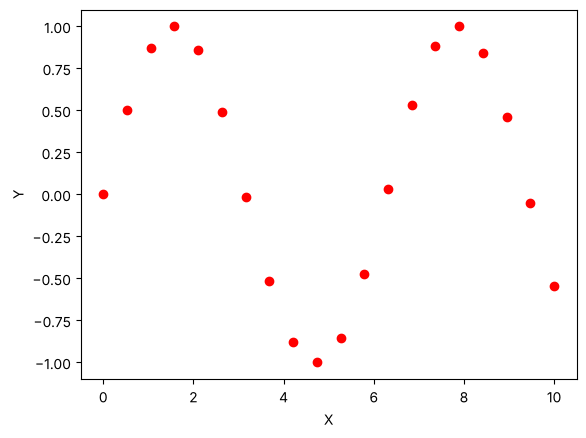

In [2]:
n = 20
x = np.linspace(0,10,n)
y = np.sin(x)

plt.scatter(x,y,color='r')
plt.xlabel('X')
plt.ylabel('Y')

# Durchgehende Sinuskurve
# plt.plot(np.linspace(0,10),np.sin(np.linspace(0,10)))

Der Wert $y$ des interpolierten Punkt an der Stelle $x$ errechnet sich durch

$y = \frac{(x_1 - x)\cdot y_0\ +\ (x - x_0)\cdot y_1}{x_1-x_0},$

wobei $(x,y)$ zwischen den Punkten $(x_0, y_0)$ und $(x_1, y_1)$ liegt. Die Normierung $\frac{1}{x_1-x_0}$ ist hingegen bei Bildern nicht notwendig, da der Abstand zwischen zwei Pixeln immer 1 ist.

Ergänzen Sie die Funktion `interpolate1d()`, welche den einzelnen $y$-Wert `y_interpolated` an der Stelle `x_interpolated` zurückgibt.
Des Weiteren bekommt die Funktion alle Punkte `x` und `y`, sowie den Index `idx` des nächstkleineren Punktes $(x_0, y_0)$.

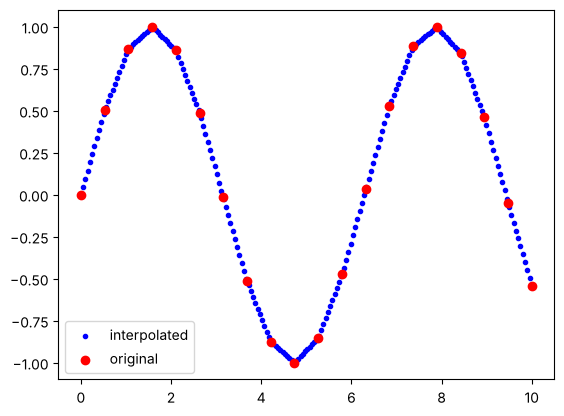

In [3]:
def interpolate1d(x_interpolated,idx,x,y):
    y_interpolated = (x[idx+1] - x_interpolated)*y[idx] + (x_interpolated - x[idx])*y[idx+1]
    norm = x[idx+1]-x[idx] #Normierung, da (im Gegensatz zu Bildern) hier die Abstände zwischen Datenpunkten nicht 1 sind
    return  y_interpolated/norm


n_interpolated = 200 #Größe des neuen Datensatzes
x_interpolated = np.linspace(0,10,n_interpolated)

# Interpolation aller Punkte
y_interpolated = np.zeros(n_interpolated)
scale = (n-1)/(n_interpolated-1) #Skalierung der Koordinaten
for i in range(n_interpolated-1):
    idx = int(i*scale) #Index des vorherigen Punkts - int schneidet Stellen nach dem Komma ab
    
    y_interpolated[i] = interpolate1d(x_interpolated[i], idx, x, y)

y_interpolated[-1] = y[-1] #Sonderfall bei letztem Punkt

# Darstellung der interpolierten Punkte
#plt.plot(x_interpolated, y_interpolated)
plt.scatter(x_interpolated, y_interpolated, color='b', marker='.', label='interpolated')
plt.scatter(x,y,color='r', label='original')
plt.legend()

Aktuell ist `n`<`n_interpolated`, sodass sich die Abtastrate erhöht. Ändern Sie die Werte von `n` und `n_interpolated`, sodass `n_interpolated`<`n` (Downsampling).

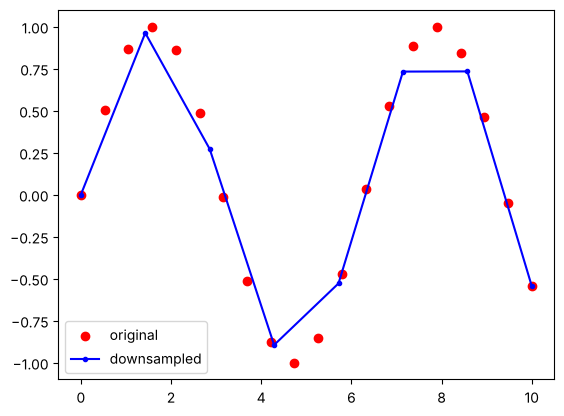

In [4]:
# Lösung: Downsampling, z. B. von 20 auf 8 Punkte
n = 20
x = np.linspace(0,10,n)
y = np.sin(x)

n_interpolated = 8 #Größe des neuen Datensatzes
x_interpolated = np.linspace(0,10,n_interpolated)

y_interpolated = np.zeros(n_interpolated)
scale = (n-1)/(n_interpolated-1)
for i in range(n_interpolated-1):
    idx = int(i*scale)
    y_interpolated[i] = interpolate1d(x_interpolated[i], idx, x, y)
y_interpolated[-1] = y[-1]

plt.scatter(x, y, color='r', label='original')
plt.plot(x_interpolated, y_interpolated, 'b.-', label='downsampled')
plt.legend()

### Bilineare Interpolation (2D)

Hier soll die Größe eines Bildes geändert werden.

Bild: [Lunch atop a Skyscraper](https://en.wikipedia.org/wiki/Lunch_atop_a_Skyscraper), 1932, RCA Building, New York

Import von Bild:

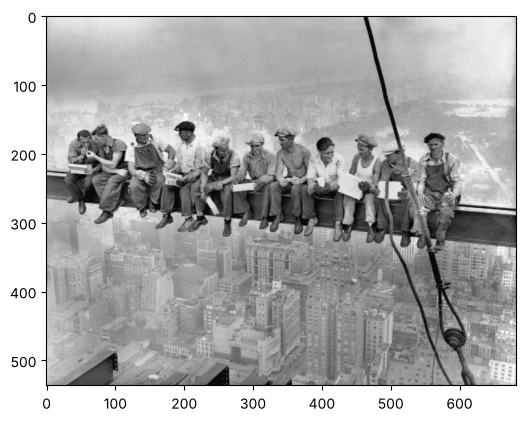

In [5]:
img = cv2.imread("Lunch_atop_a_Skyscraper.png", 0) #Argument 0 sorgt für lesen als Graustufenbild

plt.imshow(img, cmap="gray")
plt.show()

# Zahl der Grauwerte
L = 256

Bei der Bilinearen Interpolation wird der Grauwert $f$ an der Stelle $(x,y)$ mithilfe der vier umliegenden Pixelwerte errechnet:

$\begin{aligned}f(x,y) =& (i+1 - x)(j+1 - y) f(i,j)\\
&+ (x - i)(j+1 - y) f(i+1,j) \\
&+ (i+1 - x)(y - j) f(i,j+1) \\
&+ (x - i)(y - j) f(i+1,j+1)
\end{aligned}$

Schreiben Sie die Funktion `interpolate2d()`, welche die Berechnung durchführt. Eine Normierung wird hier nicht benötigt.

In [6]:
def interpolate2d(i,j,x,y,img):
    return (i+1 - x)*(j+1 - y)*img[i,j] + (x - i)*(j+1 - y)*img[i+1,j] + (i+1 - x)*(y - j)*img[i,j+1] + (x - i)*(y - j)*img[i+1,j+1]

Wenden Sie die Funktion an, um die Größe des Bildes zu verändern.

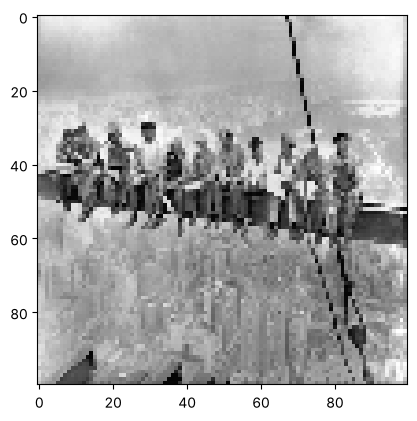

In [7]:
m_resampled, n_resampled = 100, 100 #neue Bildgröße
m, n = img.shape

img_resampled = np.zeros((m_resampled, n_resampled))
m_scale = (m - 1)/(m_resampled - 1)
n_scale = (n - 1)/(n_resampled - 1)

for k in range(m_resampled):
    for l in range(n_resampled):
        # Pixelkoordinaten im Originalbild
        x = k * m_scale
        y = l * n_scale

        # Sonderfälle für Randbereiche
        if int(x) == m-1 and int(y) == n-1:
            img_resampled[k,l] = img[int(x),int(y)]
            break
        elif int(x) == m-1:
            img_resampled[k,l] = interpolate2d(int(x)-1,int(y),x,y,img)
            continue
        elif int(y) == n-1:
            img_resampled[k,l] = interpolate2d(int(x),int(y)-1,x,y,img)
            continue

        # Interpolierte Pixel
        img_resampled[k,l] = interpolate2d(int(x),int(y),x,y,img)

plt.imshow(img_resampled, cmap="gray")
plt.show()

Interpolieren Sie nun ein Farbbild.

Bild: [Martinswand Vorbau](https://www.climbers-paradise.com/mehrseillaengen-innsbruck-tirol/location/martinswand-mehrseillaengen/), 01.11.2023

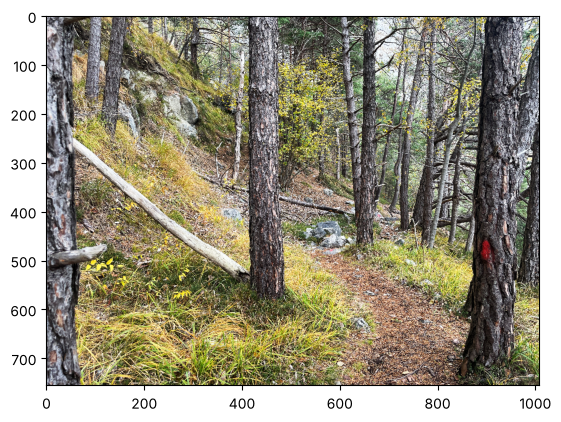

In [8]:
img = cv2.imread("martinswand_vorbau.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # OpenCV importiert als BGR. Konvertierung zu RGB für späteres Anzeigen
plt.imshow(img)
plt.show()

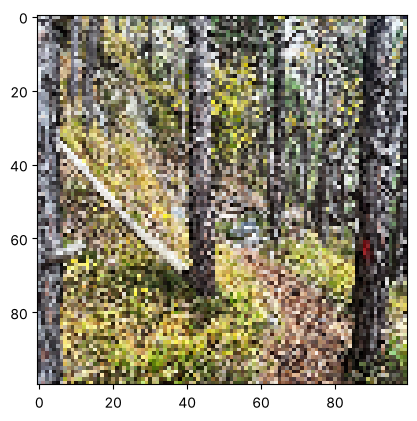

In [9]:
m_resampled, n_resampled = 100, 100 #neue Bildgröße
m, n, _ = img.shape

img_resampled = np.zeros((m_resampled, n_resampled, 3))
m_scale = (m - 1)/(m_resampled - 1)
n_scale = (n - 1)/(n_resampled - 1)

for k in range(m_resampled):
    for l in range(n_resampled):
        # Pixelkoordinaten im Originalbild
        x = k * m_scale
        y = l * n_scale

        # Sonderfälle für Randbereiche
        if int(x) == m-1 and int(y) == n-1:
            img_resampled[k,l] = img[int(x),int(y)]
            break
        elif int(x) == m-1:
            img_resampled[k,l] = interpolate2d(int(x)-1,int(y),x,y,img)
            continue
        elif int(y) == n-1:
            img_resampled[k,l] = interpolate2d(int(x),int(y)-1,x,y,img)
            continue

        # Interpolierte Pixel
        img_resampled[k,l] = interpolate2d(int(x),int(y),x,y,img)


plt.imshow(img_resampled.astype(int))
plt.show()

### Aliasing

Foto: Jeans Nahaufnahme

Aliasing tritt bei Bildern auf, wenn die Strukturen einer bestimmten Frequenz entsprechen, die die Nyquist-Frequenz überschreitet. Im folgenden ist eine Nahaufnahme einer Jeans gegeben.

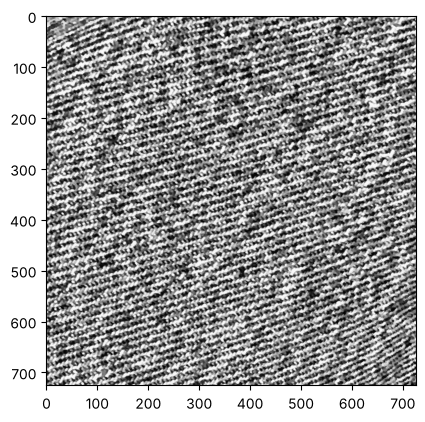

(726, 726)


In [10]:
img = cv2.imread("jeans.png",0) #Argument 0 sorgt für Einlesen als Graustufenbild

plt.imshow(img, cmap="gray")
plt.show()
print(img.shape)

Bei einer entsprechenden Umformung sieht man, dass die ursprünglich fast waagrechten Strukturen sich jetzt annähernd senkrecht durch das Bild ziehen.

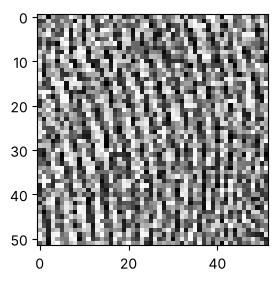

In [11]:
size = 52,52
plt.figure(figsize=(3,3))
img_alias = cv2.resize(img, size)
plt.imshow(img_alias, cmap="gray")
plt.show()

### OpenCV

OpenCV hat die Funktion [`cv2.resize()`](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html#ga47a974309e9102f5f08231edc7e7529d) implementiert, um die Größe des Bildes zu verändern. Beispielsweise wurde das Bild hier quadratisch auf 100x100 Pixel umgeformt.

Durch ersetzen des Arguments `interpolation` lassen sich auch andere Methoden anwenden, z.B.\
`INTER_LINEAR`: Bilineare Interpolation mithilfe der 2x2 umgebenden Pixel\
`INTER_CUBIC`: Bikubische Interpolation mithilfe kubischer Polynome anhand der umgebenden 4x4 Pixel\
`INTER_NEAREST`: Nearest Neighbours - die neuen Pixel nehmen den Wert des nächstgelegenen Pixels an.

Testen Sie verschiedene Interpolationsmethoden und deren Unterschiede. Versuchen Sie das Bild sowohl Up- als auch Downzusamplen.

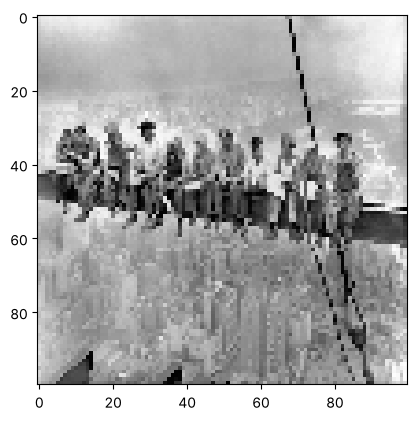

In [12]:
size = (100, 100) #neue Größe
img = cv2.imread("Lunch_atop_a_Skyscraper.png", 0)

img_resized = cv2.resize(img, size, interpolation=cv2.INTER_LINEAR)

plt.imshow(img_resized, cmap="gray")
plt.show()

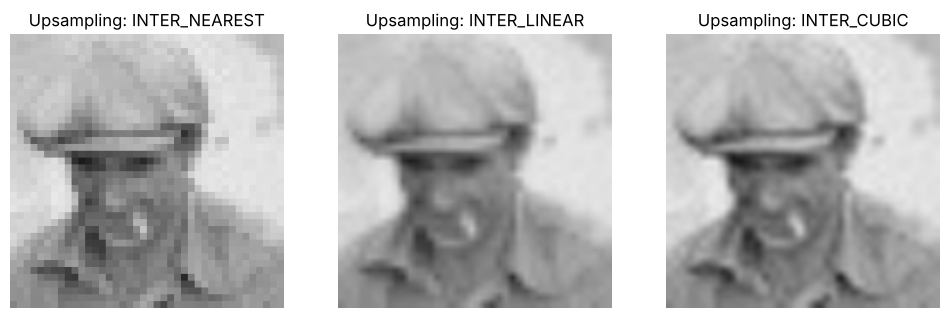

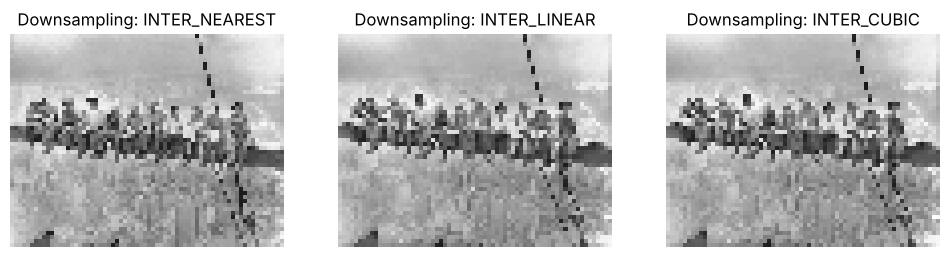

In [13]:
# Lösung: Vergleich der Interpolationsmethoden
methoden = {"INTER_NEAREST": cv2.INTER_NEAREST,
            "INTER_LINEAR": cv2.INTER_LINEAR,
            "INTER_CUBIC": cv2.INTER_CUBIC}

# Upsampling: kleinen Ausschnitt (Gesicht) auf das 6-Fache vergrößern
ausschnitt = img[170:210, 288:328]   # 40x40 Pixel
plt.figure(figsize=(12,4))
for k, (name, methode) in enumerate(methoden.items()):
    plt.subplot(1, 3, k+1)
    plt.imshow(cv2.resize(ausschnitt, (240, 240), interpolation=methode), cmap="gray", vmin=0, vmax=255)
    plt.title("Upsampling: " + name)
    plt.axis("off")
plt.show()

# Downsampling: ganzes Bild auf ein Zehntel verkleinern
# Achtung: cv2.resize erwartet die Größe als (Breite, Höhe)!
m, n = img.shape
size_klein = (n//10, m//10)
plt.figure(figsize=(12,4))
for k, (name, methode) in enumerate(methoden.items()):
    plt.subplot(1, 3, k+1)
    plt.imshow(cv2.resize(img, size_klein, interpolation=methode), cmap="gray", vmin=0, vmax=255)
    plt.title("Downsampling: " + name)
    plt.axis("off")
plt.show()

**Beobachtungen:**
- **Upsampling:** `INTER_NEAREST` wirkt blockig (jedes Pixel wird zu einem 6x6-Block), `INTER_LINEAR` weich bzw. leicht unscharf, `INTER_CUBIC` am schärfsten. An starken Kanten kann bikubisch leicht überschwingen.
- **Downsampling:** Alle drei Verfahren nutzen nur wenige Nachbarpixel, deshalb werden viele Originalpixel übersprungen – feine Strukturen flimmern bzw. es entsteht Aliasing (vgl. Jeans-Beispiel). Für das Verkleinern empfiehlt OpenCV `cv2.INTER_AREA`, das über alle Pixel der jeweiligen Fläche mittelt:

```python
img_area = cv2.resize(img, size_klein, interpolation=cv2.INTER_AREA)
```

Mit [`cv2.imwrite()`](https://docs.opencv.org/4.x/d4/da8/group__imgcodecs.html#ga8ac397bd09e48851665edbe12aa28f25) lässt sich das neue Bild abspeichern.

In [14]:
cv2.imwrite('lunch_newsize.png', img_resized) 

True